# Serie I: segmentos de variedades y lectura gerencial

**Perfiles exploratorios para describir comportamientos y orientar seguimiento.** Se utiliza el dataset entregado, con ensayos outfield (`STAGE=5`), plantía y dos socas. Cada variedad debe tener al menos dos años y dos localidades en cada corte. Las variedades con menor cobertura se conservan aparte con el motivo; no se inventa su longevidad.

Cada variedad aporta cuatro dimensiones, con igual peso después de estandarizar:

| Dimensión | Cálculo y lectura |
| --- | --- |
| Productividad | Media de azúcar por acre, primero por variedad/corte/año/localidad y después por corte. Se da el mismo peso a plantía y las dos socas. |
| Calidad | Media de TRS, en lb de azúcar por tonelada de caña, con la misma agregación. |
| Conservación en segunda soca | Azúcar medio en CROP 2 dividido entre el de CROP 0, usando **los mismos años y localidades** para esa variedad y el mismo peso por ambiente. Reduce diferencias de composición entre cortes; no sigue una misma parcela. |
| Variabilidad relativa | Desviación estándar del azúcar relativo a la mediana de variedades del mismo corte/año/localidad, centrado por variedad/corte. Un valor de 0.10 equivale a 10 puntos porcentuales en ese índice; menor valor indica menos fluctuación relativa dentro de la cobertura observada. |

La comparación ambiental de la variabilidad usa las variedades elegibles y tiene entre 6 y 11 variedades por ambiente en estos datos. Productividad y calidad describen la cobertura observada; no son efectos varietales ajustados ni estimaciones sobre un conjunto idéntico de ambientes para las 17 variedades. La fibra queda fuera por su ausencia extensa. No se usan identificadores ni conteos de cobertura para calcular distancias.

In [1]:
import sys
print("Python de ejecución:", sys.executable)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

RUTA = Path("../data/processed/serie1_etl_provisional.csv")
if not RUTA.exists():
    RUTA = Path("data/processed/serie1_etl_provisional.csv")
datos = pd.read_csv(RUTA, low_memory=False)
etapa5 = datos.loc[datos["STAGE"].eq(5)].copy()
excluir = etapa5["REQUIERE_REVISION"] | etapa5[["T_SPACRE", "TRS_TON"]].isna().any(axis=1)
filas_excluidas = etapa5.loc[excluir].copy()
filas_excluidas["MOTIVO_EXCLUSION_ANALISIS"] = np.where(
    filas_excluidas[["T_SPACRE", "TRS_TON"]].isna().any(axis=1),
    "Falta productividad o calidad para perfilar.", "Alerta de calidad en el escenario principal."
)
filas_excluidas.to_csv(RUTA.parent / "serie1_segmentacion_exclusiones.csv", index=False)
base = etapa5.loc[~excluir]
ambientes = base.groupby(["CLONE", "CROP", "YEAR", "LOC"], as_index=False)[["T_SPACRE", "TRS_TON"]].mean()
cobertura = ambientes.groupby(["CLONE", "CROP"]).agg(anios=("YEAR", "nunique"), localidades=("LOC", "nunique"))

elegibles, no_elegibles = [], []
for clon, grupo in cobertura.groupby(level="CLONE"):
    cortes = grupo.droplevel("CLONE")
    faltan = [c for c in range(3) if c not in cortes.index or cortes.loc[c, "anios"] < 2 or cortes.loc[c, "localidades"] < 2]
    if faltan:
        no_elegibles.append({"CLONE": clon, "MOTIVO": f"Cobertura insuficiente en CROP={faltan}; se requieren dos años y localidades."})
    else:
        elegibles.append(clon)
pd.DataFrame(no_elegibles).to_csv(RUTA.parent / "serie1_variedades_sin_segmento.csv", index=False)
ambientes = ambientes.loc[ambientes["CLONE"].isin(elegibles) & ambientes["CROP"].le(2)].copy()

# Referencia ambiental de la variabilidad: no se confunde el nivel medio de cada corte con su fluctuación.
clones_por_ambiente = ambientes.groupby(["CROP", "YEAR", "LOC"])["CLONE"].nunique()
ambientes["INDICE_AMBIENTE"] = ambientes["T_SPACRE"] / ambientes.groupby(["CROP", "YEAR", "LOC"])["T_SPACRE"].transform("median")
ambientes["DESVIO_AMBIENTE"] = ambientes["INDICE_AMBIENTE"] - ambientes.groupby(["CLONE", "CROP"])["INDICE_AMBIENTE"].transform("mean")
medias_corte = ambientes.groupby(["CLONE", "CROP"])[["T_SPACRE", "TRS_TON"]].mean()
perfil = medias_corte.groupby("CLONE")[["T_SPACRE", "TRS_TON"]].mean().rename(columns={"T_SPACRE": "PRODUCTIVIDAD_LB_ACRE", "TRS_TON": "CALIDAD_LB_TON"})

# Comparar plantía y segunda soca dentro de los mismos años/localidades.
pares_cortes = ambientes.pivot(index=["CLONE", "YEAR", "LOC"], columns="CROP", values="T_SPACRE")[[0, 2]]
sin_par = pares_cortes.loc[pares_cortes.isna().any(axis=1)].reset_index()
sin_par["MOTIVO_EXCLUSION_ANALISIS"] = "No hay ambos cortes en este año/localidad; se conserva para productividad, calidad y variabilidad."
sin_par.to_csv(RUTA.parent / "serie1_segmentacion_ambientes_sin_par.csv", index=False)
pares_cortes = pares_cortes.dropna()
medias_comparables = pares_cortes.groupby("CLONE")[[0, 2]].mean()
perfil["CONSERVACION_SEGUNDA_SOCA"] = medias_comparables[2] / medias_comparables[0]
perfil["INESTABILIDAD_RELATIVA"] = ambientes.groupby("CLONE")["DESVIO_AMBIENTE"].std()
variables = ["PRODUCTIVIDAD_LB_ACRE", "CALIDAD_LB_TON", "CONSERVACION_SEGUNDA_SOCA", "INESTABILIDAD_RELATIVA"]

# Los conteos describen el respaldo de cada perfil y no son entradas del agrupamiento.
soporte = pares_cortes.reset_index().groupby("CLONE").agg(
    AMBIENTES_COMPARABLES=("LOC", "size"), ANIOS_COMPARABLES=("YEAR", "nunique"), LOCALIDADES_COMPARABLES=("LOC", "nunique")
)
perfil = perfil.join(soporte)
perfil["CONSERVACION_SIN_EMPAREJAR"] = medias_corte["T_SPACRE"].unstack()[2] / medias_corte["T_SPACRE"].unstack()[0]
assert perfil[variables].notna().all().all() and np.isfinite(perfil[variables].to_numpy()).all()
assert perfil[["ANIOS_COMPARABLES", "LOCALIDADES_COMPARABLES"]].ge(2).all().all()
print(f"Filas etapa 5: {len(etapa5):,}; utilizables: {len(base):,}; excluidas con motivo: {len(filas_excluidas):,}.")
print(f"Variedades etapa 5: {etapa5['CLONE'].nunique()}; segmentadas: {len(perfil)}; sin segmento: {len(no_elegibles)}.")
print(f"Variedades por referencia ambiental: {clones_por_ambiente.min()}–{clones_por_ambiente.max()}.")
print(f"Comparaciones CROP 0–2: {len(pares_cortes)} ambientes; {len(sin_par)} sin ambos cortes, conservados aparte.")
display(perfil.round(3))

Python de ejecución: C:\Users\user\Desktop\Cursos\cesar\otros\yo\Prueba Santa Ana\.venv\Scripts\python.exe


Filas etapa 5: 14,092; utilizables: 14,029; excluidas con motivo: 63.
Variedades etapa 5: 40; segmentadas: 17; sin segmento: 23.
Variedades por referencia ambiental: 6–11.
Comparaciones CROP 0–2: 840 ambientes; 678 sin ambos cortes, conservados aparte.


,PRODUCTIVIDAD_LB_ACRE,CALIDAD_LB_TON,CONSERVACION_SEGUNDA_SOCA,INESTABILIDAD_RELATIVA,AMBIENTES_COMPARABLES,ANIOS_COMPARABLES,LOCALIDADES_COMPARABLES,CONSERVACION_SIN_EMPAREJAR
CLONE,,,,,,,,
HO05-961,8225.142,290.769,0.760,0.104,21,2,11,0.836
HO07-613,8135.057,294.314,0.679,0.126,42,4,12,0.695
HO12-615,8919.366,262.691,0.810,0.090,32,4,11,0.786
HO13-739,8089.264,274.981,0.847,0.089,25,3,11,0.803
HOCP00-950,7994.772,307.007,0.806,0.106,60,6,11,0.779
HOCP04-838,8097.584,276.687,0.784,0.101,100,12,13,0.768
HOCP09-804,8432.763,284.402,0.872,0.112,63,7,13,0.860
HOCP14-885,9013.807,279.547,0.750,0.110,18,2,11,0.805
HOCP96-540,7494.360,267.151,0.720,0.153,110,12,13,0.712


## Número de segmentos: elección por lectura gerencial

Se mantienen cuatro dimensiones directamente observables y se muestran en sus unidades originales. La estandarización evita que las unidades de productividad dominen la distancia; igual escala no significa que las dimensiones sean independientes ni que tengan el mismo valor económico.

Se revisan K=2, 3 y 4. **Se adopta K=2 por parsimonia y significado gerencial**: distinguir un perfil con mayor caída y variabilidad medias de otro con mayor productividad y conservación medias. Con K=3 y K=4 aparece un grupo de una sola variedad; se prefiere tratar ese caso como una particularidad individual antes que añadir otro segmento. Esta elección es juicio analítico explícito; no la decide el máximo de silueta ni una regla rígida de tamaño mínimo. Las métricas se muestran como diagnóstico de separación, sin probar clases naturales.

In [2]:
escalador = StandardScaler()
escalados = escalador.fit_transform(perfil[variables])
comparacion = []
ajustes = {}
for k in [2, 3, 4]:
    ajuste = KMeans(n_clusters=k, n_init=30, random_state=42).fit(escalados)
    ajustes[k] = ajuste
    tamanios = pd.Series(ajuste.labels_).value_counts()
    comparacion.append({
        "K": k, "SILUETA": silhouette_score(escalados, ajuste.labels_),
        "VARIEDADES_POR_GRUPO": sorted(tamanios.tolist()), "GRUPOS_UNITARIOS": tamanios.eq(1).sum(),
    })
comparacion = pd.DataFrame(comparacion)
display(comparacion.round(3))

k_elegido = 2
perfil["GRUPO"] = ajustes[k_elegido].labels_
orden = perfil.groupby("GRUPO")["CONSERVACION_SEGUNDA_SOCA"].mean().sort_values().index.tolist()
nombres = {grupo: f"Perfil {pos + 1}" for pos, grupo in enumerate(orden)}
perfil["SEGMENTO"] = perfil["GRUPO"].map(nombres)
resumen = perfil.groupby("SEGMENTO").agg(
    variedades=("GRUPO", "size"), productividad=("PRODUCTIVIDAD_LB_ACRE", "mean"),
    calidad=("CALIDAD_LB_TON", "mean"), conservacion=("CONSERVACION_SEGUNDA_SOCA", "mean"),
    inestabilidad=("INESTABILIDAD_RELATIVA", "mean"),
)
print("Número de segmentos elegido por interpretación:", k_elegido)
display(resumen.round(3))

# Presentación en unidades originales, con respaldo de la comparación de cortes.
tabla_gerencial = perfil[["SEGMENTO"] + variables + ["AMBIENTES_COMPARABLES", "ANIOS_COMPARABLES", "LOCALIDADES_COMPARABLES"]].copy()
tabla_gerencial["CONSERVACION_%"] = 100 * tabla_gerencial.pop("CONSERVACION_SEGUNDA_SOCA")
tabla_gerencial["VARIABILIDAD_INDICE_PP"] = 100 * tabla_gerencial.pop("INESTABILIDAD_RELATIVA")
display(tabla_gerencial.sort_values(["SEGMENTO", "CONSERVACION_%"]).round(1))
for segmento, grupo in perfil.groupby("SEGMENTO"):
    print(segmento + ": " + ", ".join(grupo.index.tolist()))
perfil.to_csv(RUTA.parent / "serie1_segmentos_variedades.csv")
resumen.to_csv(RUTA.parent / "serie1_perfiles_segmentos.csv")
comparacion.to_csv(RUTA.parent / "serie1_comparacion_segmentos.csv", index=False)

,K,SILUETA,VARIEDADES_POR_GRUPO,GRUPOS_UNITARIOS
0,2,0.254,"[5, 12]",0
1,3,0.229,"[1, 5, 11]",1
2,4,0.265,"[1, 3, 6, 7]",1


Número de segmentos elegido por interpretación: 2


,variedades,productividad,calidad,conservacion,inestabilidad
SEGMENTO,,,,,
Perfil 1,5,7996.990,290.140,0.754,0.121
Perfil 2,12,8376.219,276.844,0.826,0.098


,SEGMENTO,PRODUCTIVIDAD_LB_ACRE,CALIDAD_LB_TON,AMBIENTES_COMPARABLES,ANIOS_COMPARABLES,LOCALIDADES_COMPARABLES,CONSERVACION_%,VARIABILIDAD_INDICE_PP
CLONE,,,,,,,,
HO07-613,Perfil 1,8135.1,294.3,42,4,12,67.9,12.6
HOCP96-540,Perfil 1,7494.4,267.2,110,12,13,72.0,15.3
HO05-961,Perfil 1,8225.1,290.8,21,2,11,76.0,10.4
L03-371,Perfil 1,8135.6,291.5,42,5,11,80.3,11.8
HOCP00-950,Perfil 1,7994.8,307.0,60,6,11,80.6,10.6
HOCP14-885,Perfil 2,9013.8,279.5,18,2,11,75.0,11.0
L99-233,Perfil 2,7965.5,268.4,31,3,11,77.3,9.3
L11-183,Perfil 2,8022.7,269.9,35,4,12,78.2,10.3
HOCP04-838,Perfil 2,8097.6,276.7,100,12,13,78.4,10.1


Perfil 1: HO05-961, HO07-613, HOCP00-950, HOCP96-540, L03-371
Perfil 2: HO12-615, HO13-739, HOCP04-838, HOCP09-804, HOCP14-885, L01-283, L01-299, L11-183, L12-201, L14-267, L99-226, L99-233


## Leer las cuatro dimensiones juntas

La figura muestra todas las entradas que determinaron los grupos. Los números están en unidades originales; el color compara cada columna con las 17 variedades: azul significa valor menor y rojo valor mayor. En variabilidad, menor significa más estabilidad. Los colores no representan una puntuación general de conveniencia y las diferencias se solapan entre perfiles.

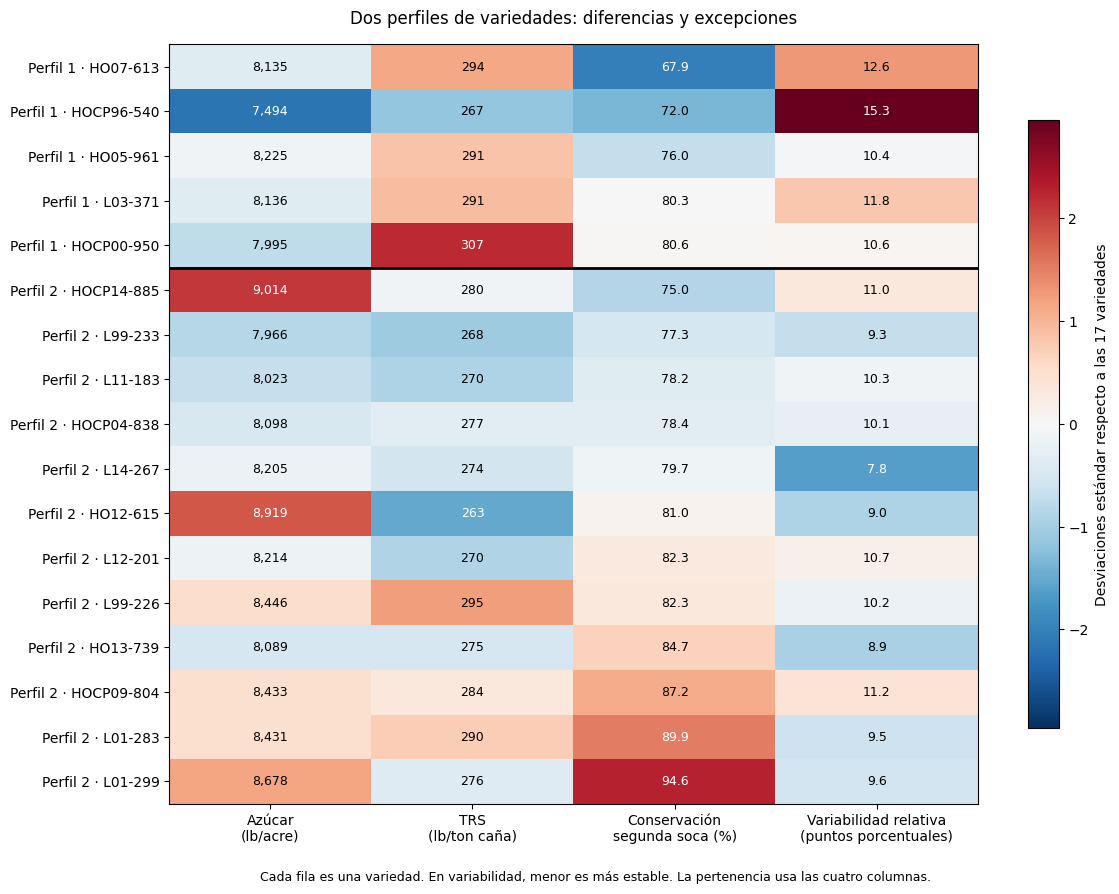

In [3]:
orden_filas = perfil.sort_values(["SEGMENTO", "CONSERVACION_SEGUNDA_SOCA"]).index
valores = perfil.loc[orden_filas, variables]
colores = pd.DataFrame(escalados, index=perfil.index, columns=variables).loc[orden_filas]
limite = np.abs(colores.to_numpy()).max()
fig, ax = plt.subplots(figsize=(12, 9))
imagen = ax.imshow(colores, cmap="RdBu_r", vmin=-limite, vmax=limite, aspect="auto")
ax.set_xticks(range(4), ["Azúcar\n(lb/acre)", "TRS\n(lb/ton caña)", "Conservación\nsegunda soca (%)", "Variabilidad relativa\n(puntos porcentuales)"])
ax.set_yticks(range(len(valores)), [f"{perfil.loc[clon, 'SEGMENTO']} · {clon}" for clon in orden_filas])
for i, clon in enumerate(orden_filas):
    for j, variable in enumerate(variables):
        valor = valores.loc[clon, variable]
        texto = f"{valor:,.0f}" if j < 2 else f"{100 * valor:.1f}"
        ax.text(j, i, texto, ha="center", va="center", color="white" if abs(colores.loc[clon, variable]) > 1.5 else "black", fontsize=9)
separacion = perfil["SEGMENTO"].eq("Perfil 1").sum() - 0.5
ax.axhline(separacion, color="black", linewidth=2)
ax.set_title("Dos perfiles de variedades: diferencias y excepciones", pad=15)
barra = fig.colorbar(imagen, ax=ax, shrink=0.8)
barra.set_label("Desviaciones estándar respecto a las 17 variedades")
fig.text(0.5, 0.015, "Cada fila es una variedad. En variabilidad, menor es más estable. La pertenencia usa las cuatro columnas.", ha="center", fontsize=9)
fig.tight_layout(rect=[0, 0.04, 1, 1])
salida_figuras = RUTA.resolve().parents[2] / "outputs"
salida_figuras.mkdir(exist_ok=True)
fig.savefig(salida_figuras / "serie1_segmentos_perfiles.png", dpi=160, bbox_inches="tight")
plt.show()

## Sensibilidad e interpretación de los límites

Se comprueban dos decisiones concretas: calcular conservación con ambientes no emparejados (versión anterior) y agrupar con un método jerárquico Ward, conservando las cuatro entradas y dos grupos. Se muestran las variedades que cambian; el ARI resume acuerdo entre particiones, no mide la certeza de pertenencia.

También se omite una dimensión cada vez. Esto cambia la pregunta de negocio, pues las cuatro dimensiones están solicitadas; sirve para saber qué información sostiene la separación, no para eliminar la dimensión que produzca peor silueta. Para comparar etiquetas de dos grupos se escoge la orientación con mayor acuerdo, ya que sus números no tienen significado propio.

In [4]:
etiquetas_completas = ajustes[k_elegido].labels_
perfil_sin_emparejar = perfil[variables].copy()
perfil_sin_emparejar["CONSERVACION_SEGUNDA_SOCA"] = perfil["CONSERVACION_SIN_EMPAREJAR"]
alternativas = {
    "Conservación sin ambientes comunes": KMeans(n_clusters=2, n_init=30, random_state=42).fit_predict(StandardScaler().fit_transform(perfil_sin_emparejar)),
    "Agrupamiento jerárquico Ward": AgglomerativeClustering(n_clusters=2, linkage="ward").fit_predict(escalados),
}
sensibilidad_metodo = []
for nombre, etiquetas in alternativas.items():
    if np.mean(etiquetas == etiquetas_completas) < 0.5:
        etiquetas = 1 - etiquetas
    cambios = perfil.index[etiquetas != etiquetas_completas].tolist()
    sensibilidad_metodo.append({
        "ALTERNATIVA": nombre, "ARI": adjusted_rand_score(etiquetas_completas, etiquetas),
        "N_CAMBIOS": len(cambios), "VARIEDADES_QUE_CAMBIAN": ", ".join(cambios),
    })
sensibilidad_metodo = pd.DataFrame(sensibilidad_metodo)
display(sensibilidad_metodo.round(3))

sensibilidad = []
for dimension in variables:
    restantes = [nombre for nombre in variables if nombre != dimension]
    etiquetas = KMeans(n_clusters=2, n_init=30, random_state=42).fit_predict(StandardScaler().fit_transform(perfil[restantes]))
    if np.mean(etiquetas == etiquetas_completas) < 0.5:
        etiquetas = 1 - etiquetas
    cambios = perfil.index[etiquetas != etiquetas_completas].tolist()
    sensibilidad.append({
        "DIMENSION_OMITIDA": dimension, "ARI_VS_SOLUCION_COMPLETA": adjusted_rand_score(etiquetas_completas, etiquetas),
        "N_CAMBIOS": len(cambios), "VARIEDADES_QUE_CAMBIAN": ", ".join(cambios),
    })
sensibilidad = pd.DataFrame(sensibilidad).set_index("DIMENSION_OMITIDA")
display(sensibilidad.round(3))
sensibilidad_metodo.to_csv(RUTA.parent / "serie1_sensibilidad_metodo_segmentos.csv", index=False)
sensibilidad.to_csv(RUTA.parent / "serie1_sensibilidad_dimensiones_segmentos.csv")

,ALTERNATIVA,ARI,N_CAMBIOS,VARIEDADES_QUE_CAMBIAN
0,Conservación sin ambientes comunes,0.758,1,HO05-961
1,Agrupamiento jerárquico Ward,0.764,1,L99-226


,ARI_VS_SOLUCION_COMPLETA,N_CAMBIOS,VARIEDADES_QUE_CAMBIAN
DIMENSION_OMITIDA,,,
PRODUCTIVIDAD_LB_ACRE,0.560,2,"HOCP14-885, L99-226"
CALIDAD_LB_TON,0.339,3,"HO05-961, HOCP00-950, L03-371"
CONSERVACION_SEGUNDA_SOCA,0.560,2,"HOCP09-804, L99-226"
INESTABILIDAD_RELATIVA,0.026,6,"HO13-739, HOCP04-838, L11-183, L12-201, L14-26..."


## Evaluación para Gerencia

Se mantienen **dos perfiles**, con las diferencias siguientes entre sus medias:

| Perfil | Variedades | Azúcar, lb/acre | TRS, lb/ton | Conservación segunda soca | Variabilidad del índice relativo |
| --- | ---: | ---: | ---: | ---: | ---: |
| 1: mayor caída y variabilidad medias | 5 | 7,997 | 290 | 75.4 % | 12.1 puntos porcentuales |
| 2: mayor productividad y conservación medias | 12 | 8,376 | 277 | 82.6 % | 9.8 puntos porcentuales |

**Perfil 1:** HO05-961, HO07-613, HOCP00-950, HOCP96-540 y L03-371. Conviene vigilar el aporte de cada soca y revisar individualmente la continuidad antes de ampliar. El TRS medio más alto no es una propiedad de todos: HOCP96-540 tiene aproximadamente 267 lb/ton, además de la mayor variabilidad relativa de las 17 variedades.

**Perfil 2:** las otras doce variedades elegibles, incluidas las tres recomendadas económicamente. Conviene evaluar continuidad en soca dentro del horizonte respaldado y comparar aportes individuales. Tampoco todas conservan igual: HOCP14-885 tiene alrededor de 75 % de conservación en ambientes comunes, pese a la mayor media del grupo. La etiqueta resume cuatro dimensiones y no fija un umbral de renovación.

Se mejora la comparación de cortes al usar los mismos años y localidades. HO05-961 pasa de 83.6 % sin emparejar a 76.0 % con ambientes comunes, y cambia de Perfil 2 a Perfil 1 respecto a la versión anterior; esta comparación solo tiene dos años. Con Ward cambia de grupo L99-226. Estos casos merecen revisión individual antes de usar la etiqueta para una decisión importante.

Las variables, sus escalas y la cobertura condicionan los grupos. La omisión de variabilidad es la que más cambia la partición; no se la elimina, porque la estabilidad forma parte de lo solicitado. Las correlaciones entre productividad, conservación y variabilidad también influyen en la distancia. Cada variedad es una observación de agrupamiento, aunque haya muchas filas de ensayos.

La certeza es exploratoria: los promedios no son efectos causales ni una garantía para cada variedad. El cociente de conservación compara plantaciones diferentes del mismo año/localidad; no sigue una misma parcela, no observa motivo de retiro ni demuestra vida útil máxima. Productividad/calidad aún corresponden a coberturas distintas entre variedades; la referencia relativa de estabilidad también cambia de composición. Los grupos orientan vigilancia y conversación gerencial; la ampliación y renovación se deciden con el análisis económico y evidencia individual. No modifican las tres recomendaciones económicas ni aportan una probabilidad de superioridad.